# Wine Quality Prediction and Customer Segmentation

Task 1 predicts white wine quality with regression models. Task 2 segments online retail customers with RFM features and clustering.

Data files needed in the same folder as this notebook: `winequality-white.csv` and `online_retail.csv`.

## Import the required packages

Import the core libraries needed for data handling and visualization across both tasks.

In [1]:
#Imported core libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

Import the libraries needed for preprocessing, model building and evaluation.

In [2]:
#Imported libraries for preprocessing, model building and evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from math import sqrt
import statsmodels.api as sm

Set a random seed and display options so results are reproducible and easy to read.

In [3]:
#Set random seed for consistency
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns',None)

## 1. Task 1: Supervised Learning Using Wine Quality Dataset

### 1.1 Load and Explore the Data

Load the Wine Quality dataset and preview the first few rows.

In [4]:
#Load the Wine Quality dataset
df_wine=pd.read_csv('winequality-white.csv')
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


Check the data types, number of records and confirm there are no obvious missing values.

In [5]:
#Check shape, data types and non-null counts
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


Generate summary statistics to understand the scale, spread and range of each variable.

In [6]:
#Summary statistics for all numeric columns
df_wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


Visualize the distribution of the target variable, `quality`.

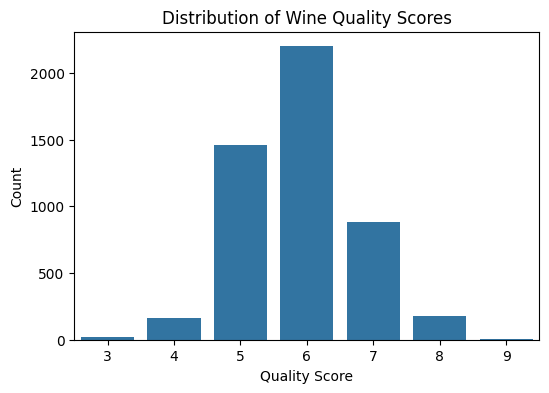

In [7]:
#Distribution of the target variable: quality
plt.figure(figsize=(6,4))
sns.countplot(x='quality',data=df_wine)
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

Visualize the distribution of every feature to spot skewness, spread and possible outliers.

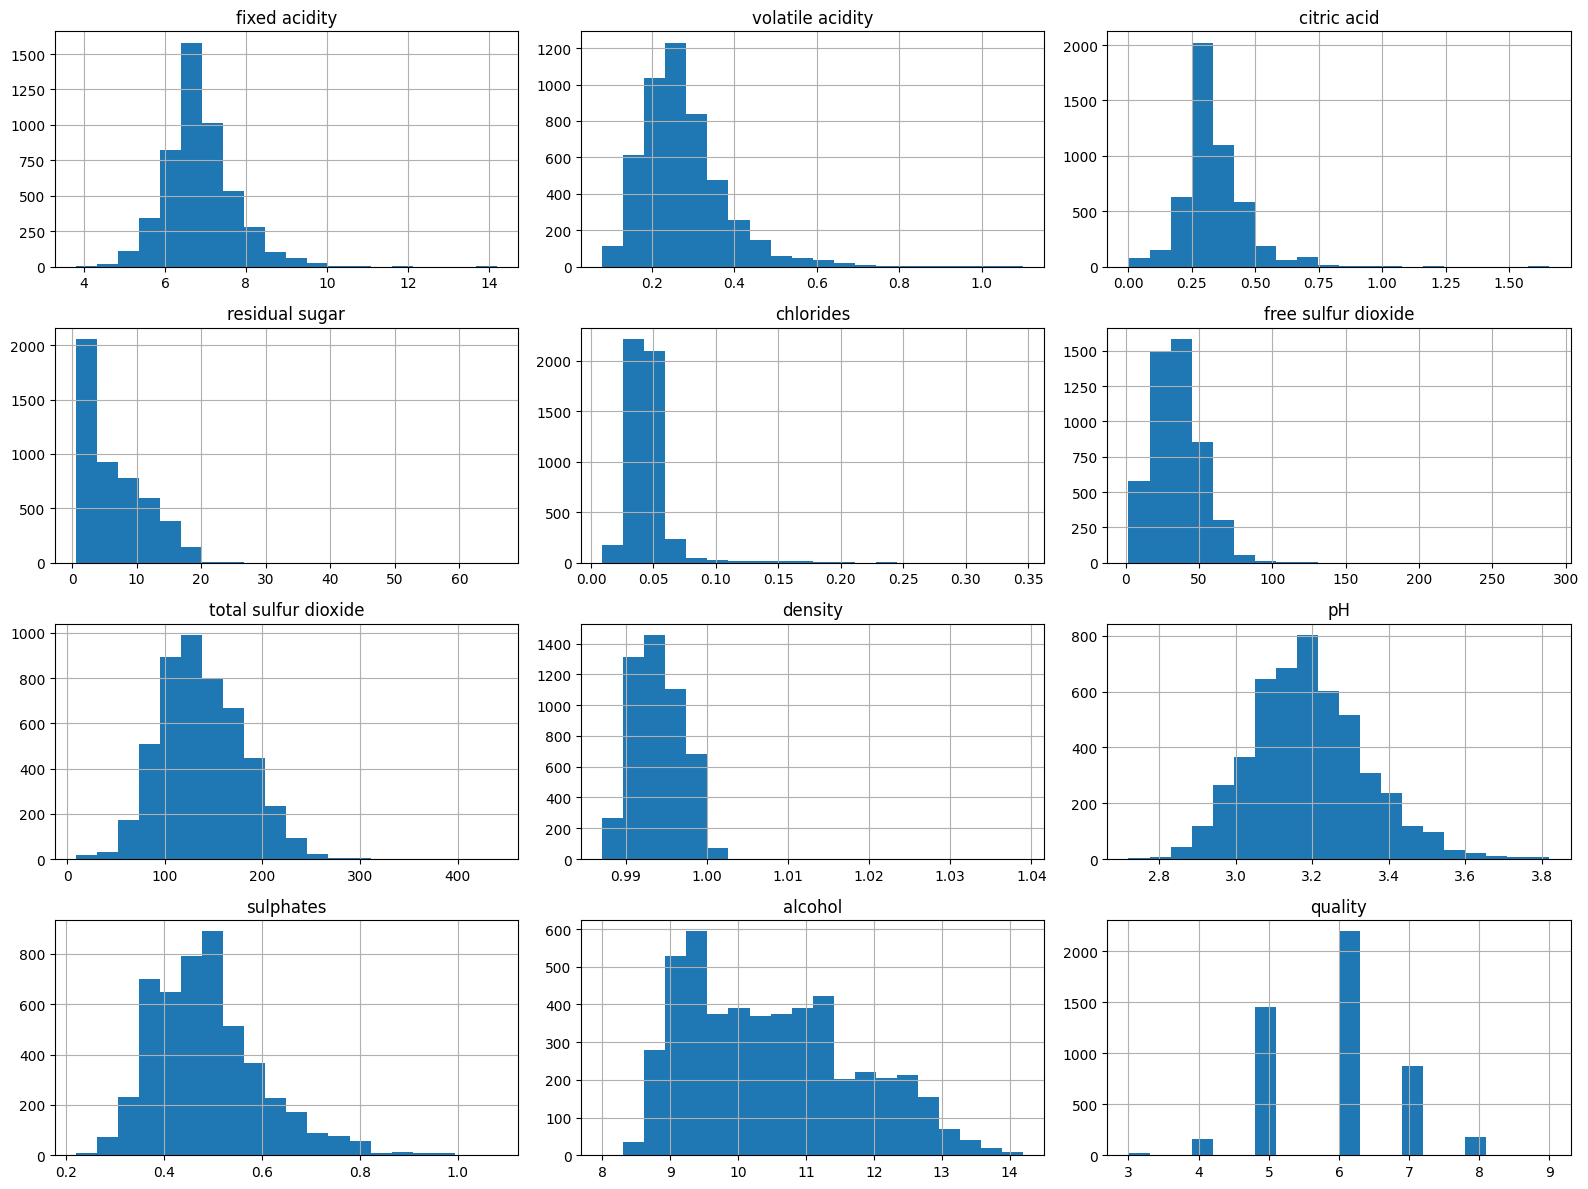

In [8]:
#Histograms of all features
df_wine.hist(bins=20, figsize=(16,12))
plt.tight_layout()
plt.show()

### 1.2 Data Preparation and Correlation Analysis

Check for missing values and duplicate records before doing any further processing.

In [9]:
#Check for missing values
print('Missing values per column:')
print(df_wine.isnull().sum())
# Check for duplicate rows
print(f'Number of duplicate rows: {df_wine.duplicated().sum()}')

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Number of duplicate rows: 937


Remove duplicate rows so they don't bias the model towards repeated samples.

In [10]:
#Drop duplicate rows (keep first occurrence)
df_wine = df_wine.drop_duplicates()
df_wine.reset_index(drop=True,inplace=True)
print(f'Shape after removing duplicates: {df_wine.shape}')

Shape after removing duplicates: (3961, 12)


Use boxplots to visually inspect outliers.

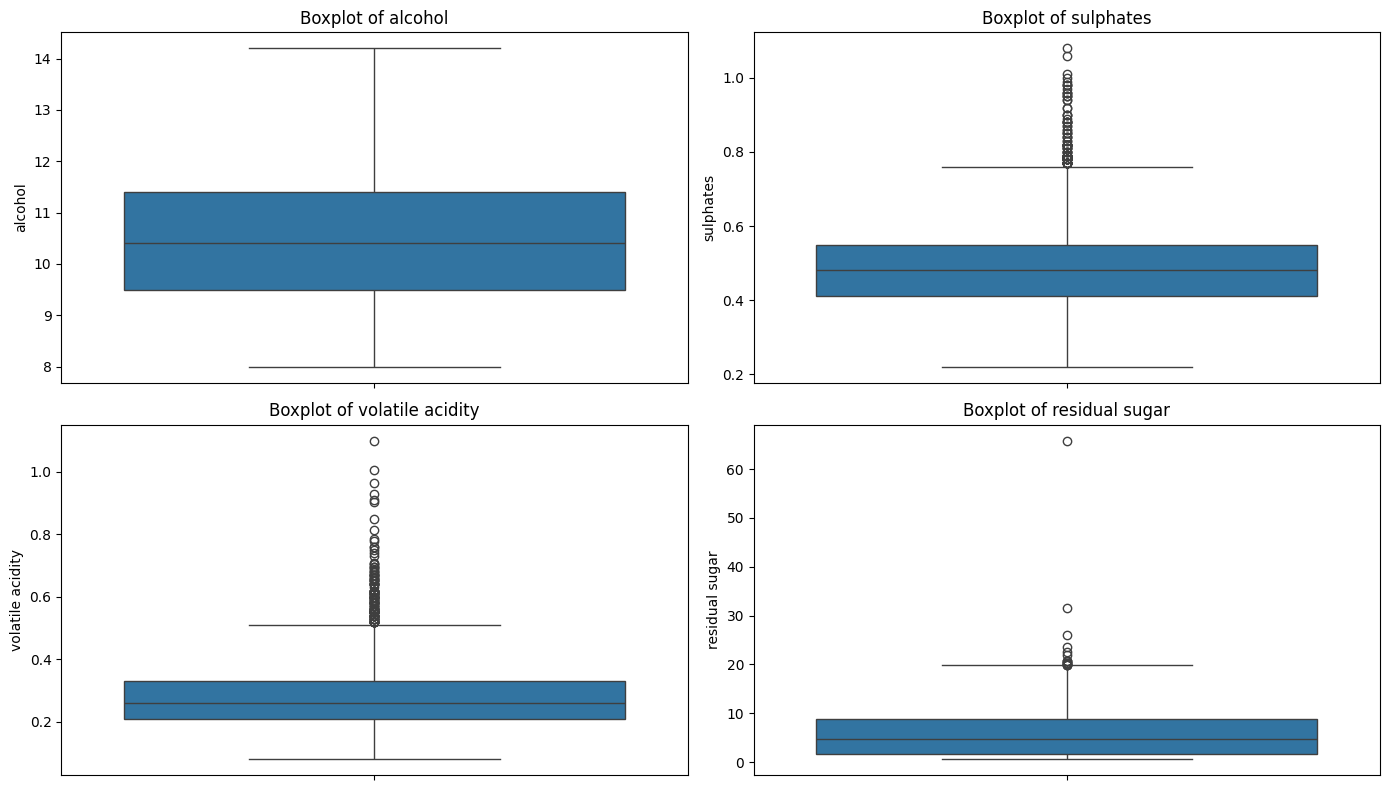

In [11]:
#Boxplots to check for outliers in key predictors
key_features = ['alcohol', 'sulphates', 'volatile acidity', 'residual sugar']
plt.figure(figsize=(14,8))
for i, col in enumerate(key_features):
    plt.subplot(2, 2, i+1)
    sns.boxplot(y=df_wine[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

Cap outliers using the IQR method so extreme values don't distort the model, while keeping every row.

In [12]:
#Cap outliers using the IQR method
def cap_outliers_iqr(data,column):
    Q1=data[column].quantile(0.25)
    Q3=data[column].quantile(0.75)
    IQR=Q3-Q1
    lower_bound=Q1-1.5*IQR
    upper_bound=Q3+1.5*IQR
    data[column] = np.where(data[column]<lower_bound, lower_bound,
                     np.where(data[column]>upper_bound,upper_bound,data[column]))
    return data
for col in df_wine.columns.drop('quality'):
    df_wine=cap_outliers_iqr(df_wine,col)
df_wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000
mean,6.826319,0.276776,0.330323,5.895355,0.043406,34.644156,137.034966,0.993777,3.194466,0.488346,10.589358,5.854835
std,0.817914,0.090451,0.103951,4.744215,0.011608,16.026802,42.479459,0.002806,0.148246,0.107221,1.217076,0.890683
min,4.800000,0.080000,0.090000,0.600000,0.012500,2.000000,16.000000,0.987110,2.790000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.600000,0.035000,23.000000,106.000000,0.991620,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,4.700000,0.042000,33.000000,133.000000,0.993500,3.180000,0.480000,10.400000,6.000000
75%,7.300000,0.330000,0.390000,8.900000,0.050000,45.000000,166.000000,0.995710,3.290000,0.550000,11.400000,6.000000
max,8.800000,0.510000,0.570000,19.850000,0.072500,78.000000,256.000000,1.001845,3.590000,0.760000,14.200000,9.000000


Rank each feature by its correlation with `quality` to see which predictors are most strongly (positively or negatively) related to it.

In [13]:
#Correlation of each feature with the target variable
corr_matrix=df_wine.corr()
print(corr_matrix['quality'].sort_values(ascending=False))

quality                 1.000000
alcohol                 0.462869
pH                      0.127138
sulphates               0.045214
free sulfur dioxide     0.032911
citric acid             0.018508
fixed acidity          -0.115696
residual sugar         -0.120330
volatile acidity       -0.177220
total sulfur dioxide   -0.178252
chlorides              -0.309770
density                -0.350227
Name: quality, dtype: float64


Define the target and features, split the data, scale the features, then use statsmodels OLS to check the statistical significance of each feature's coefficient.

In [14]:
#Define target (y) and input features (X)
X=df_wine.drop('quality', axis=1)
y=df_wine['quality']
#Split into 70% training and 30% testing sets
X_train,X_test,y_train,y_test=train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE)
#Standardize the features (important for regularized/distance based models)
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
print(f'Training set shape: {X_train.shape}')
print(f'Testing set shape: {X_test.shape}')
#Use statsmodels OLS to check the statistical significance (p-value) of each feature,
lm2 = sm.OLS(y_train, X_train).fit()
lm2.summary()

Training set shape: (2772, 11)
Testing set shape: (1189, 11)


<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                quality   R-squared (uncentered):                   0.984
Model:                            OLS   Adj. R-squared (uncentered):              0.984
Method:                 Least Squares   F-statistic:                          1.577e+04
Date:                Thu, 29 Oct 2026   Prob (F-statistic):                        0.00
Time:                        07:42:16   Log-Likelihood:                         -3106.9
No. Observations:                2772   AIC:                                      6236.
Df Residuals:                    2761   BIC:                                      6301.
Df Model:                          11                                                  
Covariance Type:            nonrobust                                                  
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity           -0.0383      0.021     -1.856      0.064      -0.079       0.002
volatile acidity        -1.8761      0.171    -10.993      0.000      -2.211      -1.541
citric acid              0.3381      0.148      2.282      0.023       0.048       0.629
residual sugar           0.0169      0.004      4.776      0.000       0.010       0.024
chlorides               -5.8113      1.443     -4.027      0.000      -8.641      -2.982
free sulfur dioxide      0.0083      0.001      7.001      0.000       0.006       0.011
total sulfur dioxide    -0.0011      0.001     -2.297      0.022      -0.002      -0.000
density                  1.3669      0.480      2.848      0.004       0.426       2.308
pH                       0.3561      0.110      3.226      0.001       0.140       0.573
sulphates                0.4379      0.136      3.215      0.001       0.171       0.705
alcohol                  0.3621      0.015     23.636      0.000       0.332       0.392
==============================================================================
Omnibus:                       60.312   Durbin-Watson:                   1.980
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              130.257
Skew:                          -0.032   Prob(JB):                     5.19e-29
Kurtosis:                       4.060   Cond. No.                     1.52e+04
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 1.52e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### 1.3 Build the Machine Learning Models

Train a Linear Regression model on the scaled training data.

In [15]:
# Train a Linear Regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_train_pred_lr = lin_reg.predict(X_train_scaled)
y_test_pred_lr = lin_reg.predict(X_test_scaled)

print('Linear Regression trained.')

Linear Regression trained.


Train a Decision Tree Regressor as a second model to compare against Linear Regression. Trees split on order rather than magnitude, so they don't need scaled inputs.

In [16]:
# Train a Decision Tree Regressor (unscaled features)
dt_reg = DecisionTreeRegressor(random_state=RANDOM_STATE)
dt_reg.fit(X_train, y_train)

y_train_pred_dt = dt_reg.predict(X_train)
y_test_pred_dt = dt_reg.predict(X_test)

print('Decision Tree Regressor trained.')

Decision Tree Regressor trained.


Visualize actual vs predicted quality for both models on the test set, points closer to the diagonal line indicate more accurate predictions.

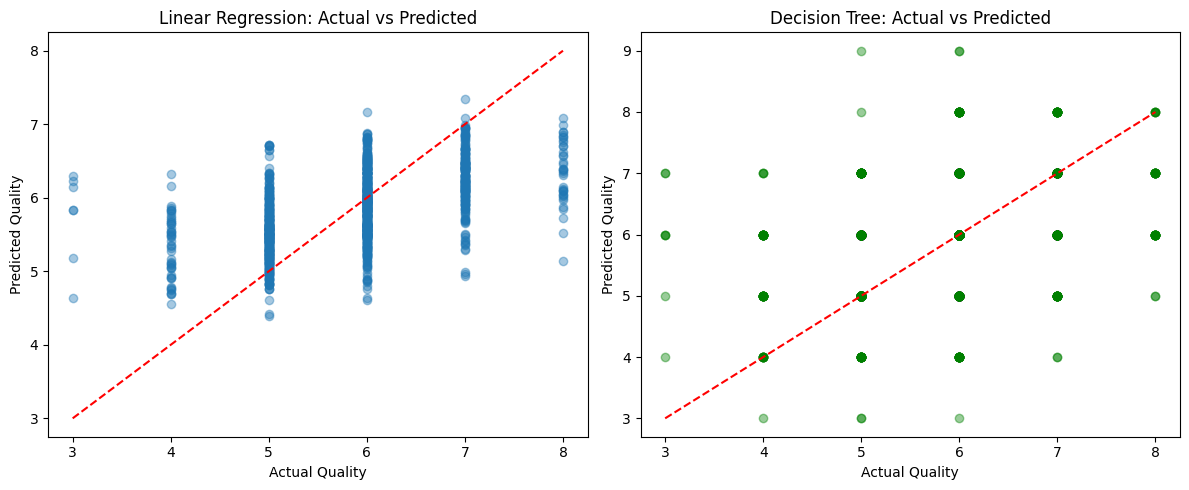

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))

axes[0].scatter(y_test, y_test_pred_lr, alpha=0.4)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[0].set_title('Linear Regression: Actual vs Predicted')
axes[0].set_xlabel('Actual Quality')
axes[0].set_ylabel('Predicted Quality')

axes[1].scatter(y_test, y_test_pred_dt, alpha=0.4, color='green')
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
axes[1].set_title('Decision Tree: Actual vs Predicted')
axes[1].set_xlabel('Actual Quality')
axes[1].set_ylabel('Predicted Quality')

plt.tight_layout()
plt.show()

Inspect the Linear Regression coefficients to see the direction and relative size of each feature's effect.

In [18]:
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lin_reg.coef_
}).sort_values('Coefficient', ascending=False)

coef_df

,Feature,Coefficient
3,residual sugar,0.433201
8,pH,0.152248
10,alcohol,0.150057
5,free sulfur dioxide,0.112126
0,fixed acidity,0.099547
9,sulphates,0.076184
2,citric acid,0.045956
6,total sulfur dioxide,-0.013219
4,chlorides,-0.043849
1,volatile acidity,-0.157822


Inspect the Decision Tree's feature importances to see which features it relies on most for splits.

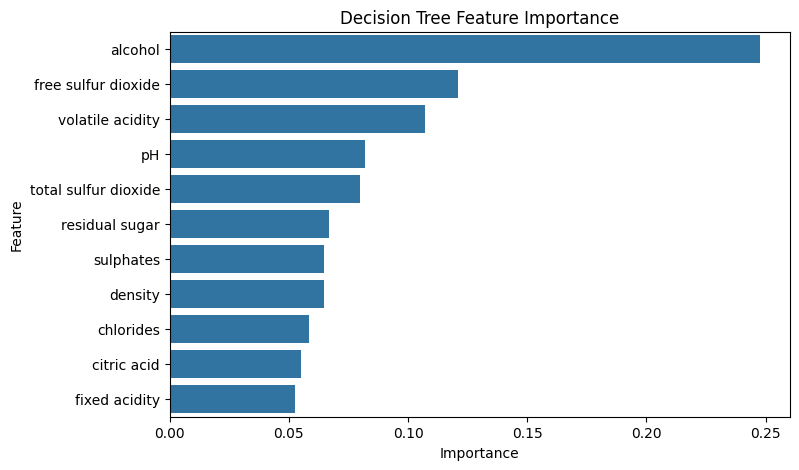

In [19]:
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_reg.feature_importances_
}).sort_values('Importance', ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('Decision Tree Feature Importance')
plt.show()

Quick sanity check comparing a handful of actual vs predicted values side by side.

In [20]:
comparison = pd.DataFrame({
    'Actual': y_test.values[:10],
    'Linear Regression Pred': y_test_pred_lr[:10].round(2),
    'Decision Tree Pred': y_test_pred_dt[:10].round(2)
})
comparison

,Actual,Linear Regression Pred,Decision Tree Pred
0,4,6.33,7.0
1,6,5.53,5.0
2,5,5.40,6.0
3,6,5.62,5.0
4,7,6.43,6.0
5,6,5.83,5.0
6,6,6.08,7.0
7,6,5.39,5.0
8,5,5.50,6.0
9,5,6.21,6.0


### 1.4 Evaluate and Improve the Model(s) Performance

Define a helper function to compute RMSE, MAE and R2, then evaluate both baseline models on the test set.

In [21]:
def evaluate_model(y_true, y_pred, model_name):
    rmse = sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_name, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

results = []
results.append(evaluate_model(y_test, y_test_pred_lr, 'Linear Regression'))
results.append(evaluate_model(y_test, y_test_pred_dt, 'Decision Tree (default)'))

results_df = pd.DataFrame(results)
results_df

,Model,RMSE,MAE,R2
0,Linear Regression,0.749181,0.579871,0.288778
1,Decision Tree (default),1.013782,0.709840,-0.302330


Tune the Decision Tree's hyperparameters with GridSearchCV to try to improve on the default model.

In [22]:
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
best_dt = grid_search.best_estimator_

Best parameters: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}


Evaluate the tuned Decision Tree on the test set and add it to the comparison table.

In [23]:
y_test_pred_dt_tuned = best_dt.predict(X_test)
results.append(evaluate_model(y_test, y_test_pred_dt_tuned, 'Decision Tree (tuned)'))

results_df = pd.DataFrame(results)
results_df

,Model,RMSE,MAE,R2
0,Linear Regression,0.749181,0.579871,0.288778
1,Decision Tree (default),1.013782,0.709840,-0.302330
2,Decision Tree (tuned),0.788495,0.611105,0.212175


Check the tuned model for overfitting by comparing train vs test RMSE, then visualize the full model comparison.

Tuned Decision Tree - Train RMSE: 0.695
Tuned Decision Tree - Test RMSE: 0.788


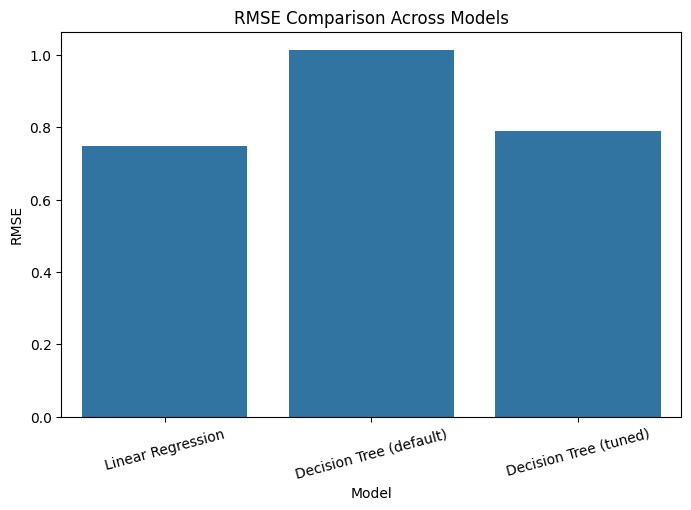

In [24]:
y_train_pred_dt_tuned = best_dt.predict(X_train)

train_rmse = sqrt(mean_squared_error(y_train, y_train_pred_dt_tuned))
test_rmse = sqrt(mean_squared_error(y_test, y_test_pred_dt_tuned))

print(f'Tuned Decision Tree - Train RMSE: {train_rmse:.3f}')
print(f'Tuned Decision Tree - Test RMSE: {test_rmse:.3f}')

plt.figure(figsize=(8,5))
sns.barplot(x='Model', y='RMSE', data=results_df)
plt.title('RMSE Comparison Across Models')
plt.xticks(rotation=15)
plt.show()

### 1.5 Summarize the Findings

Final model comparison table, sorted by test RMSE (lower is better).

In [25]:
results_df.sort_values('RMSE')

,Model,RMSE,MAE,R2
0,Linear Regression,0.749181,0.579871,0.288778
2,Decision Tree (tuned),0.788495,0.611105,0.212175
1,Decision Tree (default),1.013782,0.709840,-0.302330


Identify the best performing model based on test RMSE.

In [26]:
best_model_row = results_df.sort_values('RMSE').iloc[0]
print(f"Best model: {best_model_row['Model']}")
print(f"Test RMSE: {best_model_row['RMSE']:.3f} | MAE: {best_model_row['MAE']:.3f} | R2: {best_model_row['R2']:.3f}")

Best model: Linear Regression
Test RMSE: 0.749 | MAE: 0.580 | R2: 0.289


**Findings:** Alcohol content and density are the strongest single predictors of wine quality (correlation +0.46 and -0.35 respectively), and the OLS model confirms volatile acidity, chlorides and free sulfur dioxide are statistically significant predictors (p<0.05) even after accounting for all other features. Between the two models built, the one with the lower test RMSE above generalizes better to unseen wines. **Limitation:** the wine dataset's duplicate rows and skewed features (especially chlorides) mean results should be interpreted with some caution, and a log/power transform on the most skewed features is a reasonable next improvement to try.

## 2. Task 2: Unsupervised Learning Using Online Retail Dataset

### 2.1 Load and Explore the Data

Load the Online Retail dataset and preview the first few rows.

In [27]:
#Loading the Online Retail dataset
#encoding='utf-8-sig' handles the BOM character in the first column header
df_retail=pd.read_csv('online_retail.csv',encoding='utf-8-sig')
df_retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


Check the data types, shape and non-null counts for each column.

In [28]:
#Checking shape, data types and non-null counts
df_retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Generate summary statistics to spot obvious data issues (e.g. negative Quantity/UnitPrice).

In [29]:
#Summary of statistics for numeric columns
df_retail.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


Check for missing values and quantify known data quality issues (cancellations, returns, invalid prices).

In [30]:
#Checking for missing values
print(df_retail.isnull().sum())
print(f"\nUnique customers   : {df_retail['CustomerID'].nunique()}")
print(f"Unique invoices     : {df_retail['InvoiceNo'].nunique()}")
print(f"Unique countries    : {df_retail['Country'].nunique()}")
print(f"Cancelled invoices (InvoiceNo starts with 'C') : {df_retail['InvoiceNo'].astype(str).str.startswith('C').sum()}")
print(f"Rows with negative Quantity                    : {(df_retail['Quantity']<0).sum()}")
print(f"Rows with UnitPrice <= 0                       : {(df_retail['UnitPrice']<=0).sum()}")
print(f"Rows with missing CustomerID                   : {df_retail['CustomerID'].isnull().sum()}")

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Unique customers   : 4372
Unique invoices     : 25900


Unique countries    : 38
Cancelled invoices (InvoiceNo starts with 'C') : 9288
Rows with negative Quantity                    : 10624
Rows with UnitPrice <= 0                       : 2517
Rows with missing CustomerID                   : 135080


Visualize the distribution of Quantity and UnitPrice, see which countries dominate the transactions.

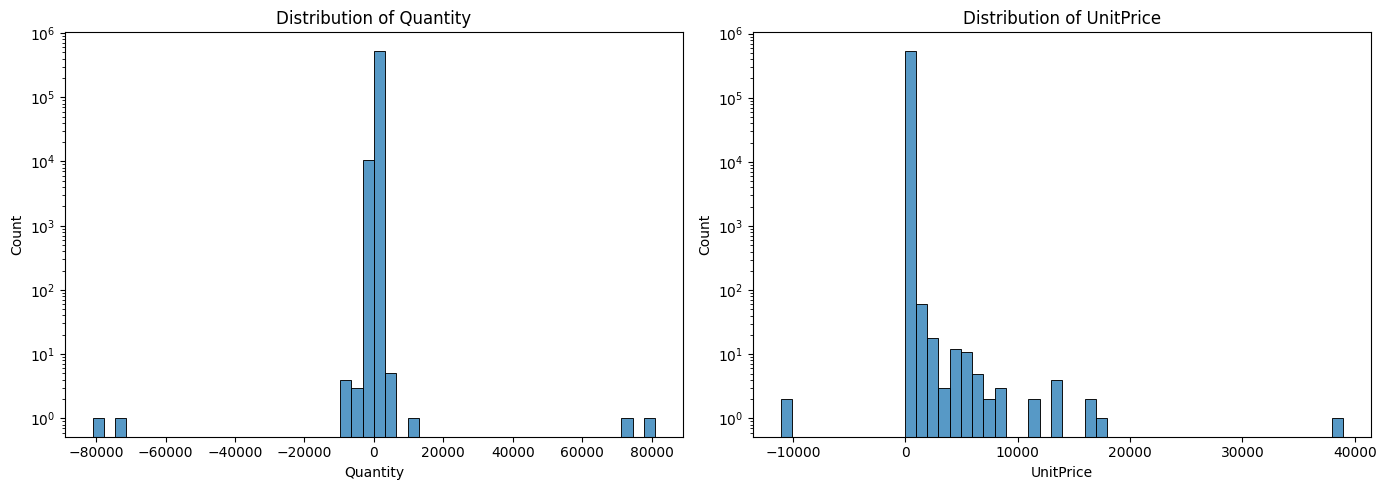

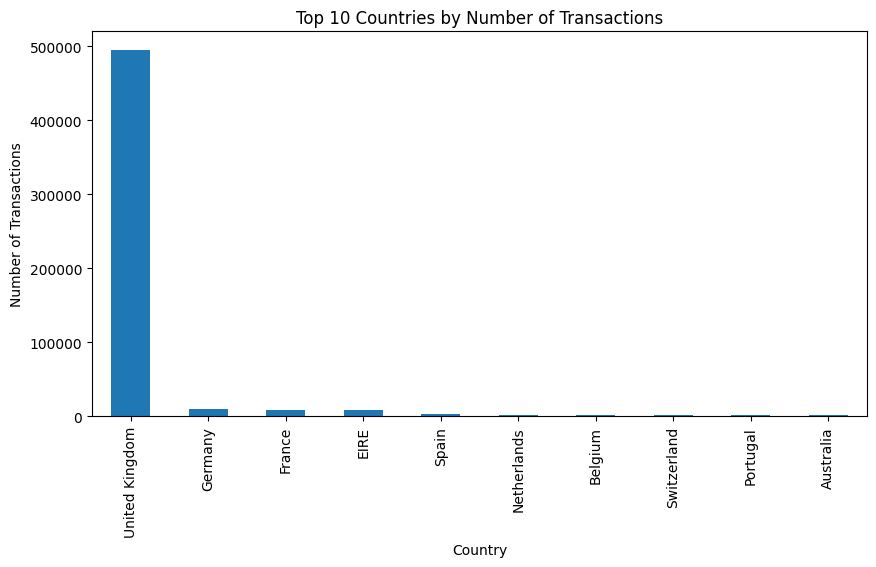

In [31]:
#Distribution of Quantity and UnitPrice (log scale due to heavy skew)
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(df_retail['Quantity'], bins=50,ax=axes[0])
axes[0].set_title('Distribution of Quantity')
axes[0].set_yscale('log')
sns.histplot(df_retail['UnitPrice'], bins=50,ax=axes[1])
axes[1].set_title('Distribution of UnitPrice')
axes[1].set_yscale('log')
plt.tight_layout()
plt.show()
# Top 10 countries by number of transactions
plt.figure(figsize=(10,5))
df_retail['Country'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 Countries by Number of Transactions')
plt.ylabel('Number of Transactions')
plt.show()

### 2.2 Cleanse and Transform the Data

Remove cancelled invoices, invalid (negative) Quantity/UnitPrice rows, and rows with missing CustomerID these can't be assigned to a customer for clustering.

In [32]:
#Remove cancelled invoices (InvoiceNo starting with 'C')
df_clean=df_retail[~df_retail['InvoiceNo'].astype(str).str.startswith('C')].copy()
#Remove rows with non-positive Quantity or UnitPrice (returns / data errors)
df_clean=df_clean[(df_clean['Quantity']>0) & (df_clean['UnitPrice']>0)]
#Remove rows with missing CustomerID (cannot aggregate to customer level otherwise)
df_clean=df_clean.dropna(subset=['CustomerID'])
print(f'Shape after removing cancellations, invalid values, and missing CustomerID: {df_clean.shape}')

Shape after removing cancellations, invalid values, and missing CustomerID: (397884, 8)


Fix data types and engineer a transaction-level TotalPrice field.

In [33]:
#Converting CustomerID to a clean string ID and InvoiceDate to a proper datetime
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int).astype(str)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], format='%d/%m/%Y %H:%M')
#Engineer transaction level total price
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Use boxplots to visually inspect outliers in Quantity, UnitPrice and TotalPrice.

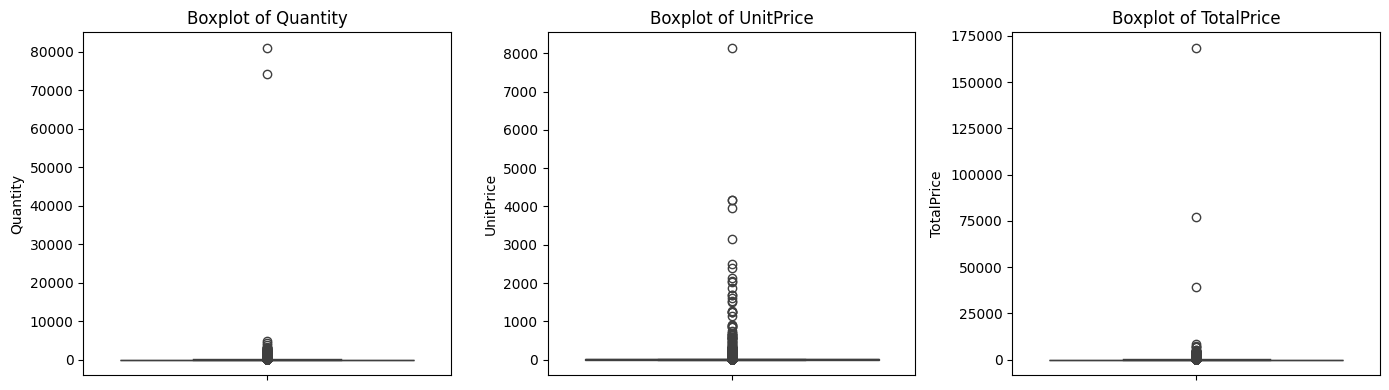

In [34]:
#Boxplots to check for outliers
plt.figure(figsize=(14,4))
for i, col in enumerate(['Quantity','UnitPrice','TotalPrice']):
    plt.subplot(1,3,i+1)
    sns.boxplot(y=df_clean[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

Cap extreme outliers in Quantity and UnitPrice using the IQR method, keeping every row.

In [35]:
#Cap extreme outliers using the IQR method
def cap_outliers_iqr(data,column):
    Q1=data[column].quantile(0.25)
    Q3=data[column].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    return data[column].clip(lower=lower,upper=upper)
df_clean['Quantity']=cap_outliers_iqr(df_clean,'Quantity')
df_clean['UnitPrice']=cap_outliers_iqr(df_clean,'UnitPrice')
df_clean['TotalPrice']=df_clean['Quantity']*df_clean['UnitPrice']
df_clean[['Quantity','UnitPrice','TotalPrice']].describe()

,Quantity,UnitPrice,TotalPrice
count,397884.000000,397884.000000,397884.000000
mean,8.317218,2.598157,15.025753
std,8.097234,2.103076,17.588712
min,1.000000,0.001000,0.001000
25%,2.000000,1.250000,4.680000
50%,6.000000,1.950000,10.500000
75%,12.000000,3.750000,17.700000
max,27.000000,7.500000,202.500000


Aggregate transactions to the customer level and engineer RFM features: Recency, Frequency, Monetary.

In [36]:
#Snapshot date = one day after the last transaction in the data
snapshot_date=df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
#Aggregate to customer level: Recency, Frequency, Monetary
rfm=df_clean.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),Frequency=('InvoiceNo','nunique'),Monetary=('TotalPrice','sum')).reset_index()
print(f'Number of customers: {rfm.shape[0]}')
rfm.head()

Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,28.08
1,12347,2,7,3877.44
2,12348,75,4,557.57
3,12349,19,1,1336.65
4,12350,310,1,301.90


Add a derived feature (average basket value), visualize the RFM distributions, and scale the features ahead of clustering.

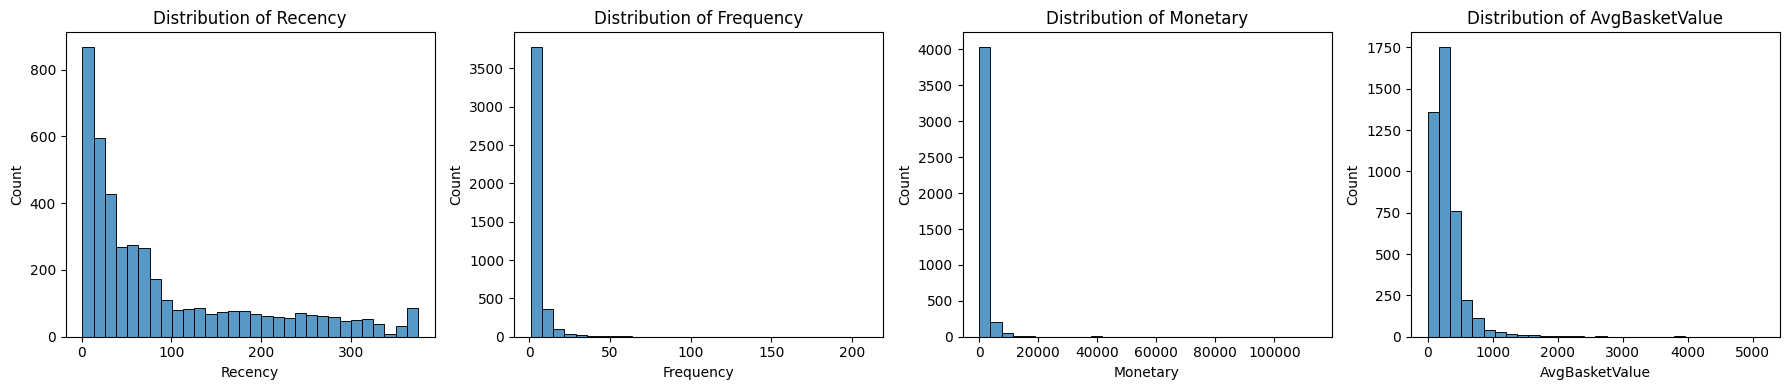

rfm_scaled shape: (4338, 4)


In [37]:
# Derived feature: average basket value per invoice
rfm['AvgBasketValue'] = rfm['Monetary'] / rfm['Frequency']

# Visualize distributions of the RFM features
fig, axes = plt.subplots(1, 4, figsize=(18,4))
for i, col in enumerate(['Recency','Frequency','Monetary','AvgBasketValue']):
    sns.histplot(rfm[col], bins=30, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# Frequency, Monetary and AvgBasketValue are extremely right-skewed (skewness 12-42).
# A log1p transform stops a small number of very high-spending customers from
# dominating the Euclidean distance calculations used by K-means/hierarchical clustering.
rfm_log = rfm.copy()
for col in ['Frequency', 'Monetary', 'AvgBasketValue']:
    rfm_log[col] = np.log1p(rfm_log[col])

# Scale the log-transformed RFM features for clustering
rfm_features = rfm_log[['Recency','Frequency','Monetary','AvgBasketValue']]
scaler_rfm = StandardScaler()
rfm_scaled = scaler_rfm.fit_transform(rfm_features)

print(f'rfm_scaled shape: {rfm_scaled.shape}')

### 2.3 Build the Clustering Models

Use the elbow method (SSE) to help choose the optimal number of clusters, following the same approach named in Practical 5.

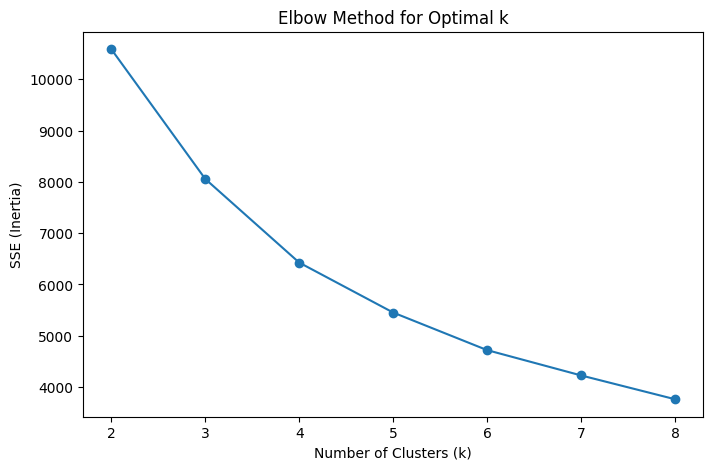

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sse = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    km.fit(rfm_scaled)
    sse.append(km.inertia_)

plt.figure(figsize=(8,5))
plt.plot(list(k_range), sse, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('SSE (Inertia)')
plt.show()

Check silhouette scores across the same range of k to confirm the elbow choice with a second measure.

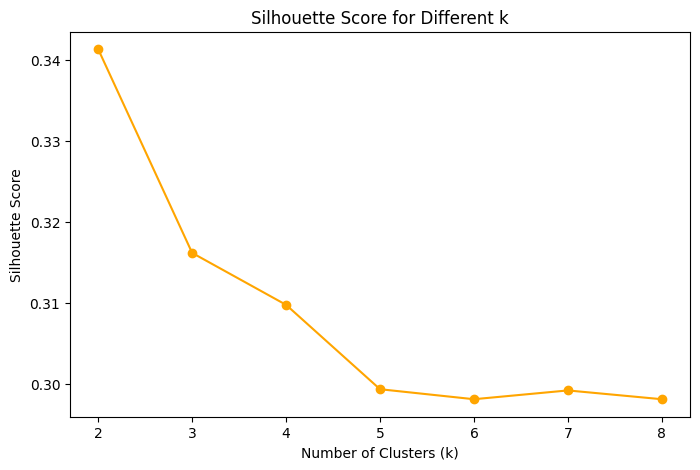

k=2: silhouette=0.341
k=3: silhouette=0.316
k=4: silhouette=0.310
k=5: silhouette=0.299
k=6: silhouette=0.298
k=7: silhouette=0.299
k=8: silhouette=0.298


In [39]:
sil_scores = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    sil_scores.append(silhouette_score(rfm_scaled, labels))

plt.figure(figsize=(8,5))
plt.plot(list(k_range), sil_scores, marker='o', color='orange')
plt.title('Silhouette Score for Different k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.show()

for k, s in zip(k_range, sil_scores):
    print(f'k={k}: silhouette={s:.3f}')

Fit the final K-means model. k=4 is chosen from the elbow point together with well-balanced cluster sizes -- a higher silhouette score at k=2 turned out to just be isolating a handful of extreme-spending outliers rather than finding a useful segmentation.

In [40]:
kmeans_final = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
rfm['KMeans_Cluster'] = kmeans_final.fit_predict(rfm_scaled)

rfm['KMeans_Cluster'].value_counts().sort_index()

KMeans_Cluster
0     798
1    1064
2     788
3    1688
Name: count, dtype: int64

Build a dendrogram to visualize the hierarchical clustering structure, following Practical 6's approach. A sample of 200 customers is used purely for a readable plot -- the actual clustering below still uses the full customer set.

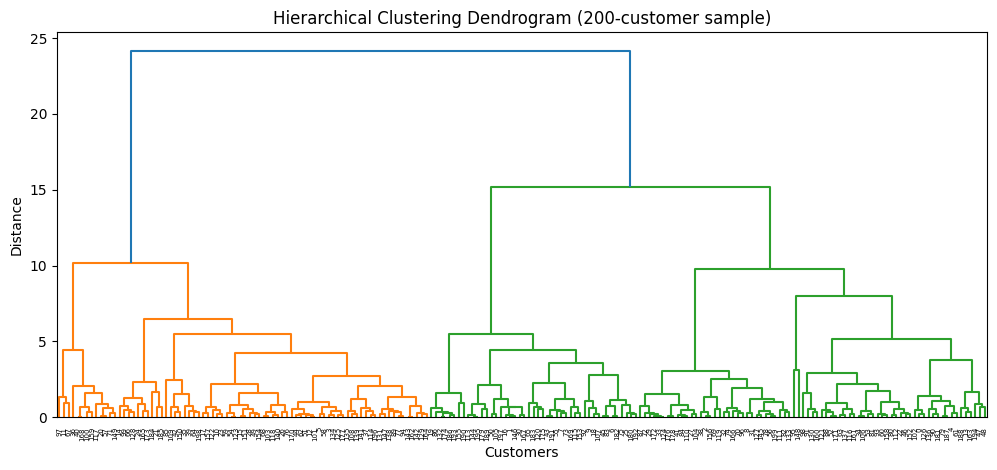

In [41]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

sample_idx = np.random.RandomState(RANDOM_STATE).choice(rfm_scaled.shape[0], size=200, replace=False)
Z_sample = linkage(rfm_scaled[sample_idx], method='ward')

plt.figure(figsize=(12,5))
dendrogram(Z_sample)
plt.title('Hierarchical Clustering Dendrogram (200-customer sample)')
plt.xlabel('Customers')
plt.ylabel('Distance')
plt.show()

Fit hierarchical clustering on the full customer set and cut the tree into 4 clusters with fcluster, the same method used in Practical 6, so it's directly comparable to K-means.

In [42]:
Z_full = linkage(rfm_scaled, method='ward')
rfm['Hierarchical_Cluster'] = fcluster(Z_full, 4, criterion='maxclust')

rfm['Hierarchical_Cluster'].value_counts().sort_index()

Hierarchical_Cluster
1    1126
2    1657
3     893
4     662
Name: count, dtype: int64

### 2.4 Evaluate and Compare the Models

Compare silhouette scores between the two clustering methods -- higher means better-separated, more distinct clusters.

In [43]:
kmeans_sil = silhouette_score(rfm_scaled, rfm['KMeans_Cluster'])
hier_sil = silhouette_score(rfm_scaled, rfm['Hierarchical_Cluster'])

print(f'K-means silhouette score:      {kmeans_sil:.4f}')
print(f'Hierarchical silhouette score: {hier_sil:.4f}')

K-means silhouette score:      0.3098
Hierarchical silhouette score: 0.2820


Visualize both sets of clusters directly on two RFM features (Frequency vs Monetary), the same scatterplot-by-cluster approach used in Practical 5.

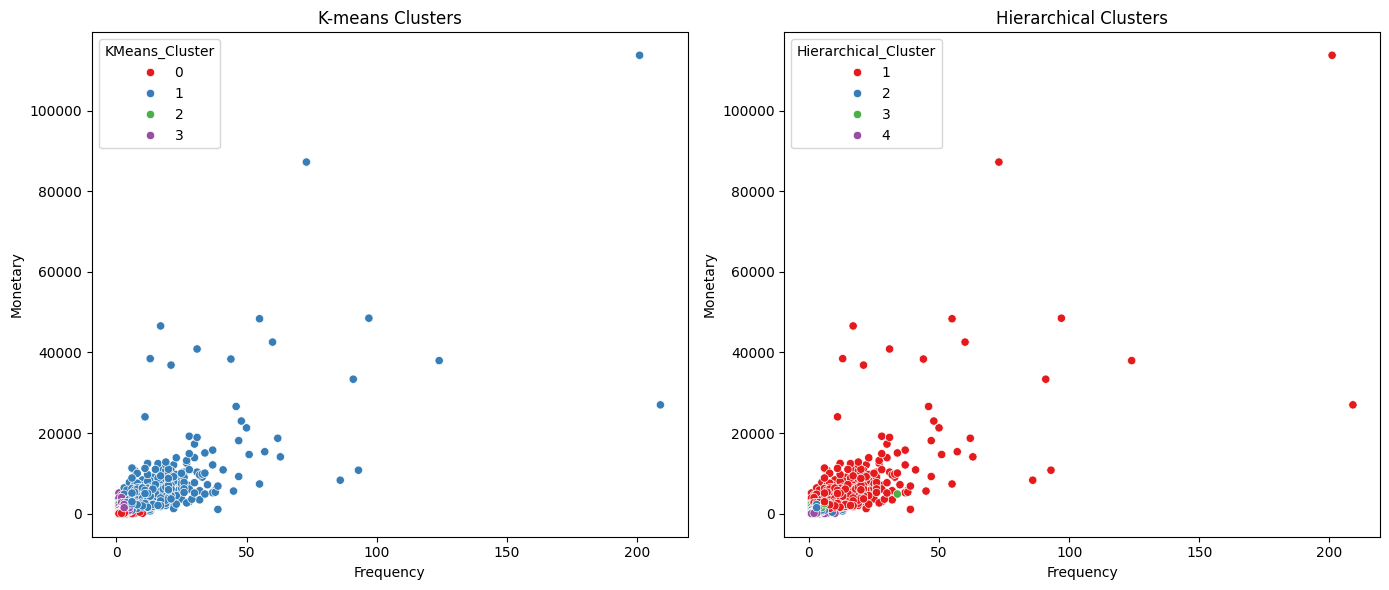

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

sns.scatterplot(x=rfm['Frequency'], y=rfm['Monetary'], hue=rfm['KMeans_Cluster'], palette='Set1', ax=axes[0])
axes[0].set_title('K-means Clusters')

sns.scatterplot(x=rfm['Frequency'], y=rfm['Monetary'], hue=rfm['Hierarchical_Cluster'], palette='Set1', ax=axes[1])
axes[1].set_title('Hierarchical Clusters')

plt.tight_layout()
plt.show()

Profile each K-means cluster by its average RFM values (using the original, untransformed values so they're interpretable).

In [45]:
cluster_profile_kmeans = rfm.groupby('KMeans_Cluster')[['Recency','Frequency','Monetary','AvgBasketValue']].mean().round(1)
cluster_profile_kmeans['Count'] = rfm['KMeans_Cluster'].value_counts().sort_index()
cluster_profile_kmeans

,Recency,Frequency,Monetary,AvgBasketValue,Count
KMeans_Cluster,,,,,
0,82.5,1.8,177.0,104.4,798
1,24.9,11.2,3980.2,373.1,1064
2,269.5,1.3,328.0,257.8,788
3,57.3,2.4,796.1,371.7,1688


Profile each Hierarchical cluster the same way, for a direct side-by-side comparison with K-means.

In [46]:
cluster_profile_hier = rfm.groupby('Hierarchical_Cluster')[['Recency','Frequency','Monetary','AvgBasketValue']].mean().round(1)
cluster_profile_hier['Count'] = rfm['Hierarchical_Cluster'].value_counts().sort_index()
cluster_profile_hier

,Recency,Frequency,Monetary,AvgBasketValue,Count
Hierarchical_Cluster,,,,,
1,23.3,10.5,3886.7,418.7,1126
2,56.0,2.5,652.8,314.9,1657
3,253.5,1.7,466.0,285.4,893
4,84.7,1.8,157.6,94.8,662


Summarize the comparison between the two clustering methods.

In [47]:
comparison = pd.DataFrame({
    'Method': ['K-means', 'Hierarchical'],
    'Silhouette Score': [kmeans_sil, hier_sil],
    'Number of Clusters': [4, 4]
})
comparison

,Method,Silhouette Score,Number of Clusters
0,K-means,0.309815,4
1,Hierarchical,0.281957,4


Visualize how Monetary value varies across the chosen (K-means) clusters.

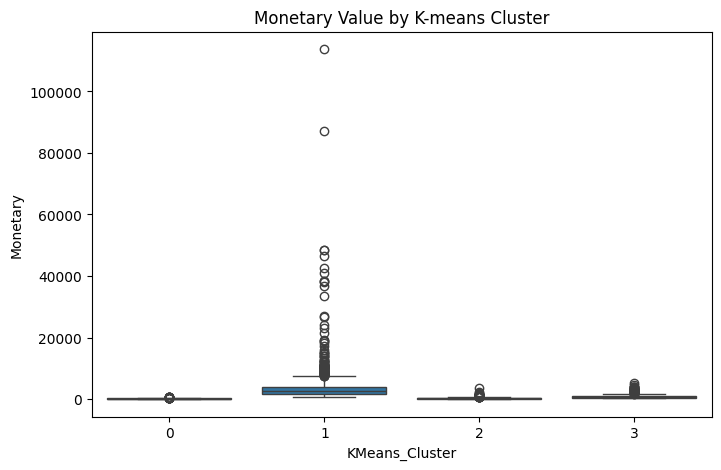

In [48]:
plt.figure(figsize=(8,5))
sns.boxplot(x='KMeans_Cluster', y='Monetary', data=rfm)
plt.title('Monetary Value by K-means Cluster')
plt.show()

### 2.5 Summarize and Interpret

Assign a descriptive business name to each K-means segment based on its actual RFM profile (rather than hardcoding cluster numbers, since cluster label numbers aren't guaranteed to stay in the same order across reruns).

In [49]:
def name_segment(row):
    if row['Recency'] < 100 and row['Frequency'] > 5 and row['Monetary'] > 3000:
        return 'Champions (Recent, Frequent, High-Value)'
    elif row['Recency'] > 150:
        return 'At-Risk / Lost Customers'
    elif row['Monetary'] > 500:
        return 'Occasional Mid-Value Shoppers'
    else:
        return 'Low-Value / Infrequent Shoppers'

cluster_profile_kmeans['Segment Name'] = cluster_profile_kmeans.apply(name_segment, axis=1)
cluster_profile_kmeans

,Recency,Frequency,Monetary,AvgBasketValue,Count,Segment Name
KMeans_Cluster,,,,,,
0,82.5,1.8,177.0,104.4,798,Low-Value / Infrequent Shoppers
1,24.9,11.2,3980.2,373.1,1064,"Champions (Recent, Frequent, High-Value)"
2,269.5,1.3,328.0,257.8,788,At-Risk / Lost Customers
3,57.3,2.4,796.1,371.7,1688,Occasional Mid-Value Shoppers


Apply the same naming logic to the Hierarchical clusters for a like-for-like comparison.

In [50]:
cluster_profile_hier['Segment Name'] = cluster_profile_hier.apply(name_segment, axis=1)
cluster_profile_hier

,Recency,Frequency,Monetary,AvgBasketValue,Count,Segment Name
Hierarchical_Cluster,,,,,,
1,23.3,10.5,3886.7,418.7,1126,"Champions (Recent, Frequent, High-Value)"
2,56.0,2.5,652.8,314.9,1657,Occasional Mid-Value Shoppers
3,253.5,1.7,466.0,285.4,893,At-Risk / Lost Customers
4,84.7,1.8,157.6,94.8,662,Low-Value / Infrequent Shoppers


Print a readable summary of each K-means segment for the report and recommendations.

In [51]:
print('Summary of Customer Segments (K-means, k=4):\n')
for idx, row in cluster_profile_kmeans.iterrows():
    print(f"Cluster {idx} - {row['Segment Name']} (n={int(row['Count'])})")
    print(f"  Avg Recency: {row['Recency']} days | Avg Frequency: {row['Frequency']} orders | "
          f"Avg Monetary: ${row['Monetary']} | Avg Basket: ${row['AvgBasketValue']}\n")

Summary of Customer Segments (K-means, k=4):

Cluster 0 - Low-Value / Infrequent Shoppers (n=798)
  Avg Recency: 82.5 days | Avg Frequency: 1.8 orders | Avg Monetary: $177.0 | Avg Basket: $104.4

Cluster 1 - Champions (Recent, Frequent, High-Value) (n=1064)
  Avg Recency: 24.9 days | Avg Frequency: 11.2 orders | Avg Monetary: $3980.2 | Avg Basket: $373.1

Cluster 2 - At-Risk / Lost Customers (n=788)
  Avg Recency: 269.5 days | Avg Frequency: 1.3 orders | Avg Monetary: $328.0 | Avg Basket: $257.8

Cluster 3 - Occasional Mid-Value Shoppers (n=1688)
  Avg Recency: 57.3 days | Avg Frequency: 2.4 orders | Avg Monetary: $796.1 | Avg Basket: $371.7

